In [13]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random
from keras.datasets import mnist
from keras.models import Sequential 

In [14]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [15]:
print(x_train.shape)
print(y_train.shape)

print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [16]:
x_train = x_train / 255
x_test = x_test / 255

In [17]:
import keras

model = Sequential()

model.add(keras.layers.Flatten(input_shape=(28,28)))

model.add(keras.layers.Dense(
    128,
    activation="relu"
))

model.add(keras.layers.Dense(
    10,
    activation="softmax"
))

c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [18]:
model.compile(
    optimizer="sgd",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
neunet = model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=5
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8353 - loss: 0.6526 - val_accuracy: 0.9016 - val_loss: 0.3595
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9054 - loss: 0.3392 - val_accuracy: 0.9200 - val_loss: 0.2932
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9186 - loss: 0.2907 - val_accuracy: 0.9278 - val_loss: 0.2614
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9272 - loss: 0.2607 - val_accuracy: 0.9331 - val_loss: 0.2395
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9332 - loss: 0.2383 - val_accuracy: 0.9361 - val_loss: 0.2229


In [20]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test
)

print("loss = %.3f" % test_loss)
print("accuracy = %.3f" % test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step - accuracy: 0.9361 - loss: 0.2229
loss = 0.223
accuracy = 0.936


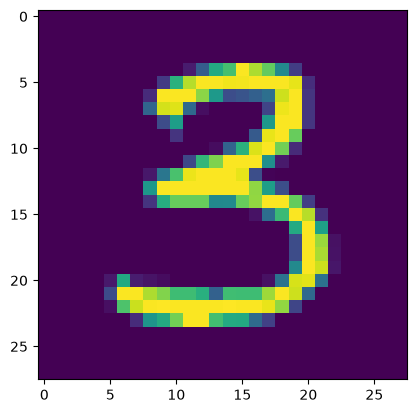

In [31]:
n = random.randint(0,9999)
plt.imshow(x_test[n])
plt.show()

In [32]:
prediction = model.predict(x_test)
print("the handwritten in the image is: ", np.argmax(prediction[n]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 570us/step
the handwritten in the image is:  3


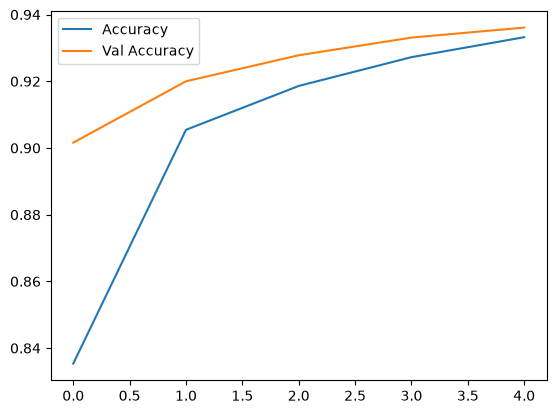

In [21]:
import matplotlib.pyplot as plt

plt.plot(neunet.history['accuracy'], label='Accuracy')
plt.plot(neunet.history['val_accuracy'], label='Val Accuracy')

plt.legend()
plt.show()

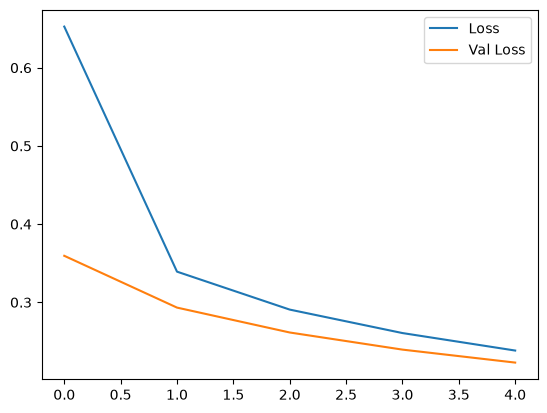

In [22]:
plt.plot(neunet.history['loss'], label='Loss')
plt.plot(neunet.history['val_loss'], label='Val Loss')

plt.legend()
plt.show()